In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuración visual de los gráficos
plt.rcParams["figure.figsize"] = (10, 8)
plt.rcParams.update({'font.size': 12})
plt.rcParams["font.family"] = "serif"

print("Cargando bases de datos COSMIC...")
# Ajusta la ruta si tus archivos están en otra carpeta (ej. './data/cosmic...')
cosmic_gm = pd.read_csv('C:/Users/J/Desktop/Proyecto BDCP/cosmic-gm_teorico.csv', sep=',')
cosmic_variants = pd.read_csv('C:/Users/J/Desktop/Proyecto BDCP/cosmic-variants_teorico.csv', sep=',')

# Filtrar el archivo General (gm) por el gen ZWINT usando el nombre exacto de columna
zwint_gm = cosmic_gm[cosmic_gm['Gene Name'] == 'ZWINT']

# El archivo de variantes ya está específico para el gen (no tiene columna Gene Name)
zwint_variants = cosmic_variants.copy()

print(f"Mutaciones totales en ZWINT (GM): {zwint_gm.shape[0]}")
print(f"Variantes únicas en ZWINT (Variants): {zwint_variants.shape[0]}")

Cargando bases de datos COSMIC...
Mutaciones totales en ZWINT (GM): 369
Variantes únicas en ZWINT (Variants): 301


## Results: Tissue Distribution
Análisis de la distribución de tejidos afectados por mutaciones en el gen ZWINT utilizando la base de datos COSMIC.

7                          Lung
5               Large intestine
14                      Stomach
8                    Oesophagus
3                   Endometrium
6                         Liver
10                     Pancreas
17                Urinary tract
1                        Breast
16    Upper aerodigestive tract
11                     Prostate
13              Small intestine
9                         Ovary
2                        Cervix
0                 Biliary tract
12                         Skin
15                      Thyroid
4                        Kidney
Name: Primary Tissue, dtype: object 7     60
5     50
14    41
8     27
3     19
6     13
10    12
17    11
1     10
16     8
11     8
13     5
9      5
2      5
0      4
12     3
15     2
4      1
Name: Histology, dtype: int64


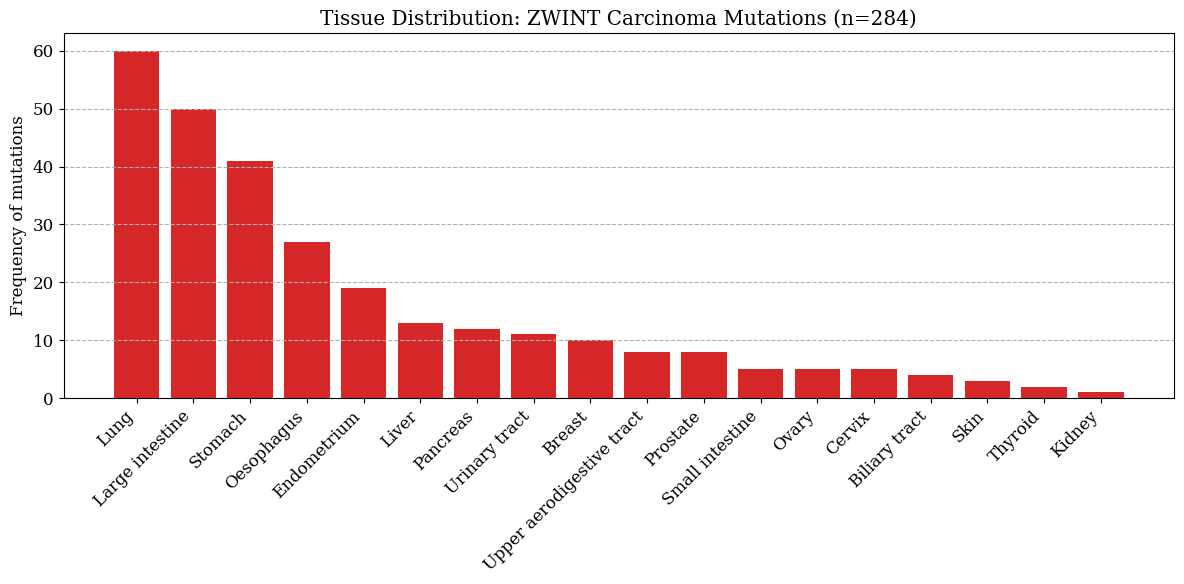

In [13]:
# Filtramos para enfocarnos en los Carcinomas (puedes quitar el filtro si quieres ver todos)
carc_zwint = zwint_gm[zwint_gm['Histology'] == 'Carcinoma']
cosmic_rows = carc_zwint.shape[0]

# Agrupamos por tejido primario
carc_sum = carc_zwint.groupby('Primary Tissue')['Histology'].count().reset_index()
carc_ord = carc_sum.sort_values('Histology', ascending=False)
print(carc_ord['Primary Tissue'][:], carc_ord['Histology'][:])

plt.figure(figsize=(12, 6))
plt.bar(carc_ord['Primary Tissue'], height=carc_ord['Histology'], width=0.8, color='tab:red')
plt.xticks(rotation=45, ha='right')
plt.title(f'Tissue Distribution: ZWINT Carcinoma Mutations (n={cosmic_rows})')
plt.ylabel('Frequency of mutations')
plt.grid(axis='y', ls='--')
plt.tight_layout()
plt.show()

1         Substitution - Missense
4                         Unknown
3    Substitution - coding silent
2         Substitution - Nonsense
0               Nonstop extension
Name: Type, dtype: object 1    176
4    124
3     47
2     21
0      1
Name: Count, dtype: int64


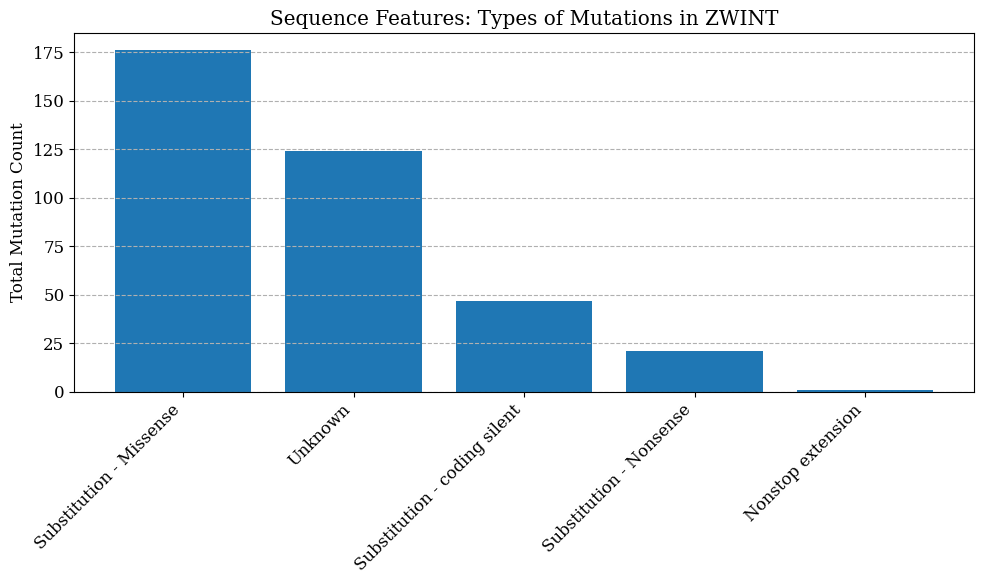

In [14]:
# Analizamos la frecuencia de los distintos tipos de mutaciones (Nonsense, Missense, etc.)
seq_features = zwint_variants.groupby('Type')['Count'].sum().reset_index()
seq_ord = seq_features.sort_values('Count', ascending=False)

print(seq_ord['Type'], seq_ord['Count'])
plt.figure(figsize=(10, 6))
plt.bar(seq_ord['Type'], height=seq_ord['Count'], color='tab:blue')
plt.xticks(rotation=45, ha='right')
plt.title('Sequence Features: Types of Mutations in ZWINT')
plt.ylabel('Total Mutation Count')
plt.grid(axis='y', ls='--')
plt.tight_layout()
plt.show()

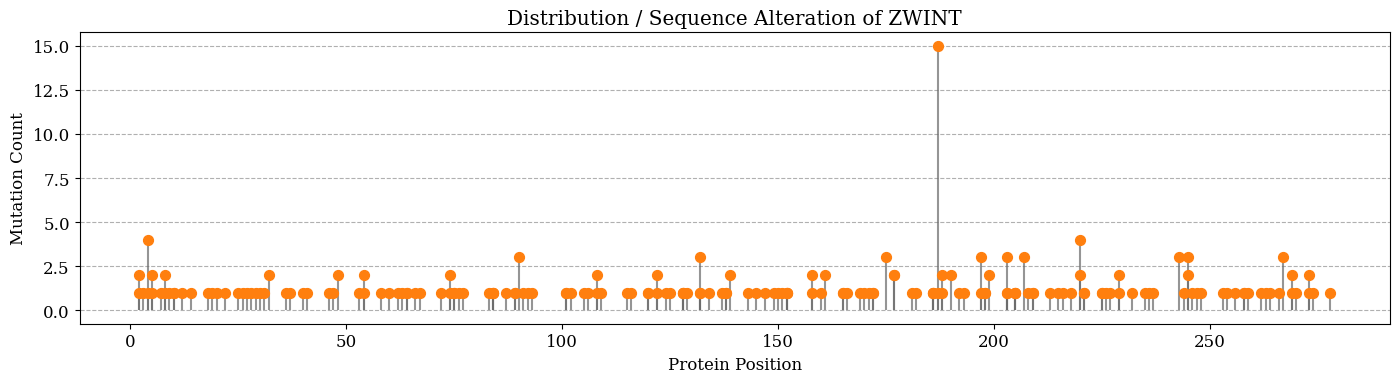

In [7]:
# Mostramos en qué posiciones exactas ocurren las mutaciones a lo largo de la secuencia
plt.figure(figsize=(14, 4))
plt.vlines(x=zwint_variants['Position'], ymin=0, ymax=zwint_variants['Count'], color='dimgrey', alpha=0.7)
plt.scatter(x=zwint_variants['Position'], y=zwint_variants['Count'], color='tab:orange', s=50, zorder=3)

plt.title('Distribution / Sequence Alteration of ZWINT')
plt.xlabel('Protein Position')
plt.ylabel('Mutation Count')
plt.grid(axis='y', ls='--')
plt.tight_layout()
plt.show()

In [15]:
print(zwint_variants['Position'],zwint_variants['Count'])

0      2.0
1      2.0
2      3.0
3      4.0
4      4.0
      ... 
296    NaN
297    NaN
298    NaN
299    NaN
300    NaN
Name: Position, Length: 301, dtype: float64 0      2
1      1
2      1
3      1
4      4
      ..
296    1
297    1
298    2
299    1
300    1
Name: Count, Length: 301, dtype: int64
